In [1]:
import os
import json
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from datasets import load_from_disk
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: mps


In [2]:
processed_dataset = load_from_disk(
    "../data/processed/scienceqa_preprocessed"
)

test_data = processed_dataset["test"]

print("Test samples:", len(test_data))

Test samples: 2017


In [3]:
class EvaluationDataset(Dataset):

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        return {
            "input_ids": torch.tensor(
                sample["input_ids"], dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                sample["attention_mask"], dtype=torch.long
            ),
            "option_mask": torch.tensor(
                sample["option_mask"], dtype=torch.bool
            ),
            "pixel_values": torch.tensor(
                sample["pixel_values"], dtype=torch.float32
            ),
            "labels": torch.tensor(
                sample["labels"], dtype=torch.long
            )
        }


test_dataset = EvaluationDataset(test_data)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

print("Test batches:", len(test_loader))

Test batches: 253


In [4]:
RESULTS_DIR = "../results"
EVALUATION_DIR = "../results/evaluation"

os.makedirs(EVALUATION_DIR, exist_ok=True)

model_paths = {
    "Text-only BERT":
        "../results/text_only_bert/best_model.pth",

    "Early Fusion V2":
        "../results/early_fusion_v2/best_model.pth",

    "Early Fusion V3":
        "../results/early_fusion_v3/best_model.pth",

    "Intermediate Fusion":
        "../results/intermediate_fusion_v1/best_intermediate_fusion_v1.pth"
}

for name, path in model_paths.items():
    print(
        name,
        "FOUND" if os.path.exists(path) else "MISSING"
    )

Text-only BERT FOUND
Early Fusion V2 FOUND
Early Fusion V3 FOUND
Intermediate Fusion FOUND


In [5]:

import torch
import torch.nn as nn
from transformers import AutoModel

BERT_MODEL = "bert-base-uncased"
VIT_MODEL = "google/vit-base-patch16-224"


# 1. Text-only BERT
class TextOnlyBERT(nn.Module):
    def __init__(self, bert):
        super().__init__()
        self.bert = bert
        self.scorer = nn.Linear(768, 1)

        for param in self.bert.parameters():
            param.requires_grad = False

    def train(self, mode=True):
        super().train(mode)
        self.bert.eval()
        return self

    def forward(self, input_ids, attention_mask, option_mask):
        batch_size, num_choices, seq_length = input_ids.shape

        input_ids = input_ids.view(-1, seq_length)
        attention_mask = attention_mask.view(-1, seq_length)

        valid_indices = option_mask.view(-1).nonzero(as_tuple=True)[0]

        with torch.no_grad():
            outputs = self.bert(
                input_ids=input_ids[valid_indices],
                attention_mask=attention_mask[valid_indices]
            )
            features = outputs.last_hidden_state[:, 0, :]

        valid_scores = self.scorer(features).squeeze(-1)

        scores = torch.full(
            (batch_size * num_choices,),
            float("-inf"),
            device=input_ids.device
        )
        scores[valid_indices] = valid_scores

        return scores.view(batch_size, num_choices)


# 2. Early Fusion V2
class EarlyFusionModelV2(nn.Module):
    def __init__(self, bert, vit):
        super().__init__()
        self.bert = bert
        self.vit = vit

        self.fusion = nn.Sequential(
            nn.Linear(768 + 768, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 1)
        )

    def train(self, mode=True):
        super().train(mode)
        self.vit.eval()
        return self

    def forward(self, input_ids, attention_mask, pixel_values, option_mask):
        batch_size, num_choices, seq_length = input_ids.shape

        input_ids = input_ids.view(-1, seq_length)
        attention_mask = attention_mask.view(-1, seq_length)

        valid_indices = option_mask.view(-1).nonzero(as_tuple=True)[0]

        text_output = self.bert(
            input_ids=input_ids[valid_indices],
            attention_mask=attention_mask[valid_indices]
        )
        text_features = text_output.last_hidden_state[:, 0, :]

        with torch.no_grad():
            image_output = self.vit(pixel_values=pixel_values)
            image_features = image_output.last_hidden_state[:, 0, :]

        image_features = image_features.repeat_interleave(
            num_choices, dim=0
        )[valid_indices]

        combined = torch.cat((text_features, image_features), dim=1)
        valid_scores = self.fusion(combined).squeeze(-1)

        scores = torch.full(
            (batch_size * num_choices,),
            float("-inf"),
            device=input_ids.device
        )
        scores[valid_indices] = valid_scores

        return scores.view(batch_size, num_choices)


# 3. Early Fusion V3
class EarlyFusionModelV3(nn.Module):
    def __init__(self, bert, vit):
        super().__init__()
        self.bert = bert
        self.vit = vit

        self.fusion = nn.Sequential(
            nn.Linear(2304, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, 1)
        )

    def forward(self, input_ids, attention_mask, pixel_values, option_mask):
        batch_size, num_choices, seq_length = input_ids.shape

        flat_input_ids = input_ids.view(-1, seq_length)
        flat_attention_mask = attention_mask.view(-1, seq_length)

        text_outputs = self.bert(
            input_ids=flat_input_ids,
            attention_mask=flat_attention_mask
        )
        text_features = text_outputs.last_hidden_state[:, 0, :]

        image_outputs = self.vit(pixel_values=pixel_values)
        image_tokens = image_outputs.last_hidden_state

        cls_features = image_tokens[:, 0, :]
        patch_features = image_tokens[:, 1:, :].mean(dim=1)

        image_features = torch.cat(
            [cls_features, patch_features], dim=1
        )
        image_features = image_features.repeat_interleave(
            num_choices, dim=0
        )

        combined = torch.cat([text_features, image_features], dim=1)
        scores = self.fusion(combined).view(batch_size, num_choices)

        return scores.masked_fill(option_mask == 0, float("-inf"))


# 4. Intermediate Fusion V1
class IntermediateFusionModelV1(nn.Module):
    def __init__(self, bert, vit):
        super().__init__()
        self.bert = bert
        self.vit = vit

        self.cross_attention = nn.MultiheadAttention(
            embed_dim=768,
            num_heads=8,
            dropout=0.1,
            batch_first=True
        )

        self.fusion_norm = nn.LayerNorm(1536)

        self.fusion = nn.Sequential(
            nn.Linear(1536, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, 1)
        )

    def forward(self, input_ids, attention_mask, pixel_values, option_mask):
        batch_size, num_choices, seq_length = input_ids.shape

        flat_input_ids = input_ids.reshape(-1, seq_length)
        flat_attention_mask = attention_mask.reshape(-1, seq_length)

        text_outputs = self.bert(
            input_ids=flat_input_ids,
            attention_mask=flat_attention_mask
        )
        text_tokens = text_outputs.last_hidden_state

        image_outputs = self.vit(pixel_values=pixel_values)
        image_tokens = image_outputs.last_hidden_state

        image_tokens = image_tokens.repeat_interleave(
            num_choices, dim=0
        )

        attended_image, _ = self.cross_attention(
            query=text_tokens,
            key=image_tokens,
            value=image_tokens,
            need_weights=False
        )

        text_mask = flat_attention_mask.unsqueeze(-1).float()

        text_features = (
            (text_tokens * text_mask).sum(dim=1)
            / text_mask.sum(dim=1).clamp(min=1)
        )

        image_features = attended_image.mean(dim=1)

        combined = torch.cat(
            [text_features, image_features], dim=1
        )
        combined = self.fusion_norm(combined)

        scores = self.fusion(combined).reshape(
            batch_size, num_choices
        )

        return scores.masked_fill(option_mask == 0, float("-inf"))


In [6]:

from transformers import AutoModel

def load_checkpoint(model, checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
    model.load_state_dict(checkpoint)
    model.to(device)
    model.eval()
    return model


models = {
    "Text-only BERT": TextOnlyBERT(
        AutoModel.from_pretrained(BERT_MODEL)
    ),
    "Early Fusion V2": EarlyFusionModelV2(
        AutoModel.from_pretrained(BERT_MODEL),
        AutoModel.from_pretrained(VIT_MODEL)
    ),
    "Early Fusion V3": EarlyFusionModelV3(
        AutoModel.from_pretrained(BERT_MODEL),
        AutoModel.from_pretrained(VIT_MODEL)
    ),
    "Intermediate Fusion": IntermediateFusionModelV1(
        AutoModel.from_pretrained(BERT_MODEL),
        AutoModel.from_pretrained(VIT_MODEL)
    )
}

for name, model in models.items():
    model_paths_for_load = model_paths[name]
    models[name] = load_checkpoint(model, model_paths_for_load)
    print(f"{name}: checkpoint loaded")


W1111 21:51:09.733000 14103 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

... (6 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Text-only BERT: checkpoint loaded
Early Fusion V2: checkpoint loaded
Early Fusion V3: checkpoint loaded
Intermediate Fusion: checkpoint loaded


In [7]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)
from tqdm.auto import tqdm
import numpy as np
import pandas as pd

criterion = nn.CrossEntropyLoss()

evaluation_results = {}
all_predictions = {}

for model_name, model in models.items():

    print(f"\nEvaluating: {model_name}")

    model.eval()

    total_loss = 0.0
    y_true = []
    y_pred = []

    with torch.no_grad():

        for batch in tqdm(test_loader):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            option_mask = batch["option_mask"].to(device)
            labels = batch["labels"].to(device)

            if model_name == "Text-only BERT":
                logits = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    option_mask=option_mask
                )
            else:
                pixel_values = batch["pixel_values"].to(device)

                logits = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    pixel_values=pixel_values,
                    option_mask=option_mask
                )

            loss = criterion(logits, labels)

            predictions = torch.argmax(logits, dim=1)

            total_loss += loss.item() * labels.size(0)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    results = {
        "Model": model_name,
        "Test Loss": total_loss / len(test_dataset),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred)
    }

    evaluation_results[model_name] = results

    all_predictions[model_name] = {
        "y_true": y_true,
        "y_pred": y_pred,
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=[0, 1, 2, 3, 4]
        ),
        "classification_report": classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2, 3, 4],
            zero_division=0,
            output_dict=True
        )
    }

    print(f"Accuracy: {results['Accuracy']:.4f}")
    print(f"Test Loss: {results['Test Loss']:.4f}")

print("\nAll model evaluations completed.")



Evaluating: Text-only BERT


  0%|          | 0/253 [00:00<?, ?it/s]

Accuracy: 0.5677
Test Loss: 0.8934

Evaluating: Early Fusion V2


  0%|          | 0/253 [00:00<?, ?it/s]

Accuracy: 0.5910
Test Loss: 0.7839

Evaluating: Early Fusion V3


  0%|          | 0/253 [00:00<?, ?it/s]

Accuracy: 0.5845
Test Loss: 0.8294

Evaluating: Intermediate Fusion


  0%|          | 0/253 [00:00<?, ?it/s]

Accuracy: 0.6867
Test Loss: 0.6906

All model evaluations completed.


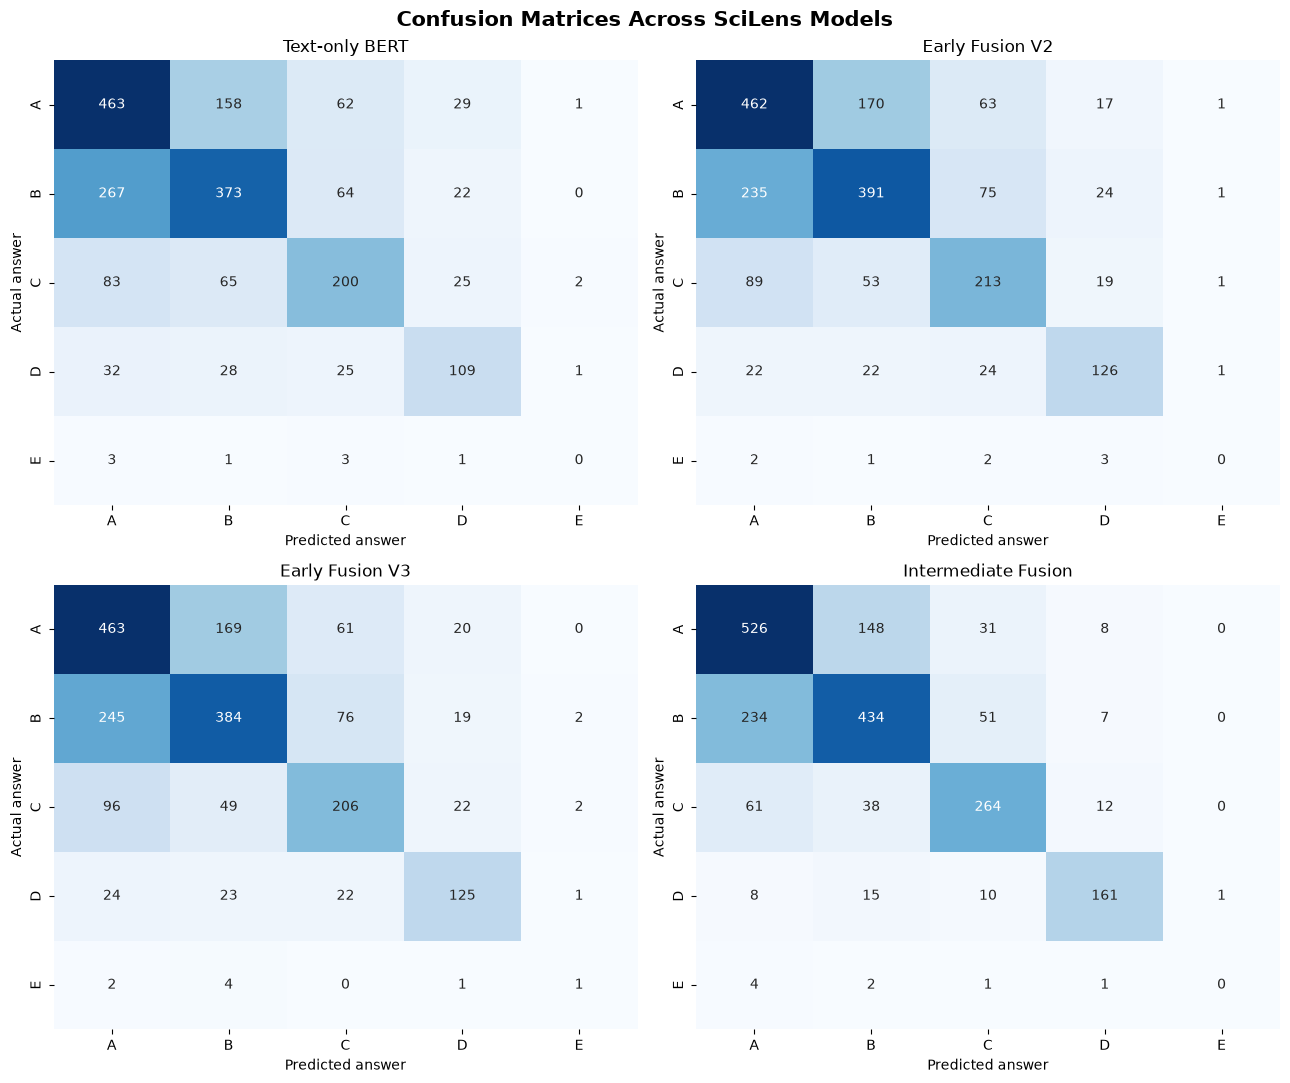

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

model_names = list(all_predictions.keys())

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

for ax, model_name in zip(axes, model_names):

    cm = all_predictions[model_name]["confusion_matrix"]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["A", "B", "C", "D", "E"],
        yticklabels=["A", "B", "C", "D", "E"]
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted answer")
    ax.set_ylabel("Actual answer")

plt.suptitle(
    "Confusion Matrices Across SciLens Models",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(EVALUATION_DIR, "confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [9]:

class_results = []

for model_name, prediction_data in all_predictions.items():

    report = prediction_data["classification_report"]

    for class_id, class_name in enumerate(["A", "B", "C", "D", "E"]):

        metrics = report[str(class_id)]

        class_results.append({
            "Model": model_name,
            "Answer Class": class_name,
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1-score": metrics["f1-score"],
            "Support": metrics["support"]
        })

class_df = pd.DataFrame(class_results)

class_df.to_csv(
    os.path.join(EVALUATION_DIR, "class_level_metrics.csv"),
    index=False
)

display(
    class_df[class_df["Model"] == "Intermediate Fusion"].style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}"
    })
)


,Model,Answer Class,Precision,Recall,F1-score,Support
15,Intermediate Fusion,A,0.631,0.738,0.680,713.000000
16,Intermediate Fusion,B,0.681,0.598,0.637,726.000000
17,Intermediate Fusion,C,0.739,0.704,0.721,375.000000
18,Intermediate Fusion,D,0.852,0.826,0.839,195.000000
19,Intermediate Fusion,E,0.000,0.000,0.000,8.000000


In [10]:

# Class-level metrics for all four models

all_class_metrics = []

for model_name, prediction_data in all_predictions.items():

    report = prediction_data["classification_report"]

    for class_id, class_name in enumerate(["A", "B", "C", "D", "E"]):

        metrics = report[str(class_id)]

        all_class_metrics.append({
            "Model": model_name,
            "Answer Class": class_name,
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1-score": metrics["f1-score"],
            "Support": int(metrics["support"])
        })

all_models_class_df = pd.DataFrame(all_class_metrics)

# Display all models
display(
    all_models_class_df.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}"
    })
)

# Save results
all_models_class_df.to_csv(
    os.path.join(EVALUATION_DIR, "all_models_class_metrics.csv"),
    index=False
)

print("Saved: all_models_class_metrics.csv")


,Model,Answer Class,Precision,Recall,F1-score,Support
0,Text-only BERT,A,0.546,0.649,0.593,713
1,Text-only BERT,B,0.597,0.514,0.552,726
2,Text-only BERT,C,0.565,0.533,0.549,375
3,Text-only BERT,D,0.586,0.559,0.572,195
4,Text-only BERT,E,0.000,0.000,0.000,8
5,Early Fusion V2,A,0.570,0.648,0.607,713
6,Early Fusion V2,B,0.614,0.539,0.574,726
7,Early Fusion V2,C,0.565,0.568,0.566,375
8,Early Fusion V2,D,0.667,0.646,0.656,195
9,Early Fusion V2,E,0.000,0.000,0.000,8


Saved: all_models_class_metrics.csv


In [11]:

overall_metrics = pd.DataFrame(evaluation_results.values())

display(overall_metrics.style.format({
    "Test Loss": "{:.4f}",
    "Accuracy": "{:.2%}",
    "Macro Precision": "{:.4f}",
    "Macro Recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Balanced Accuracy": "{:.4f}"
}))

overall_metrics.to_csv(
    os.path.join(EVALUATION_DIR, "overall_model_metrics.csv"),
    index=False
)


,Model,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,Text-only BERT,0.8934,56.77%,0.4588,0.4511,0.4533,0.4511
1,Early Fusion V2,0.7839,59.10%,0.4832,0.4801,0.4806,0.4801
2,Early Fusion V3,0.8294,58.45%,0.5136,0.4987,0.5042,0.4987
3,Intermediate Fusion,0.6906,68.67%,0.5808,0.5730,0.5754,0.5730


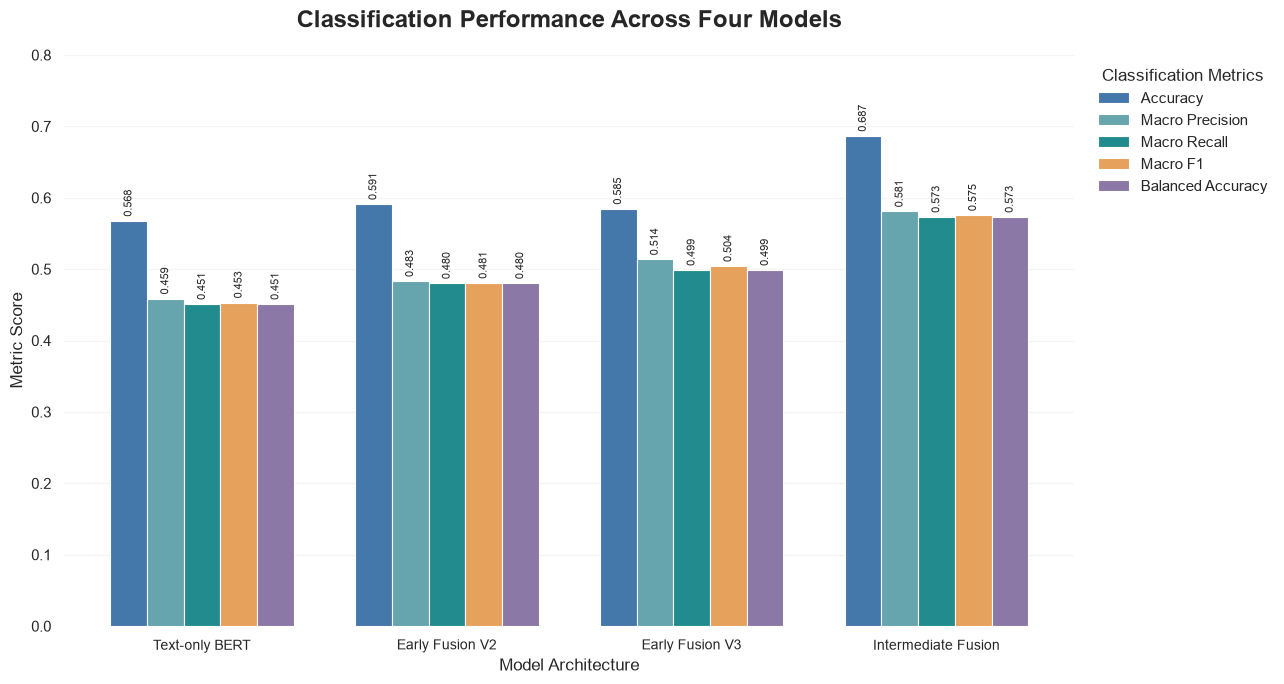

In [21]:

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Data from evaluation_results
metrics_df = pd.DataFrame(evaluation_results.values())

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Balanced Accuracy"
]

model_names = metrics_df["Model"].tolist()

# Professional colour palette
colors = ["#4477AA", "#66A5AD", "#228B8D", "#E6A15C", "#8B78A6"]

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(13, 7))

x = np.arange(len(model_names))
width = 0.15

for i, (metric, color) in enumerate(zip(metric_columns, colors)):
    offset = (i - 2) * width

    bars = ax.bar(
        x + offset,
        metrics_df[metric],
        width=width,
        label=metric,
        color=color,
        edgecolor="white",
        linewidth=0.8
    )

    ax.bar_label(
        bars,
        labels=[f"{v:.3f}" for v in metrics_df[metric]],
        padding=3,
        fontsize=8,
        rotation=90
    )

ax.set_title(
    "Classification Performance Across Four Models",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Metric Score", fontsize=12)
ax.set_xlabel("Model Architecture", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=10)

ax.set_ylim(0, 0.78)
ax.set_yticks(np.arange(0, 0.81, 0.1))

ax.legend(
    title="Classification Metrics",
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False
)

ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()

plt.savefig(
    os.path.join(EVALUATION_DIR, "classification_metrics_comparison.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


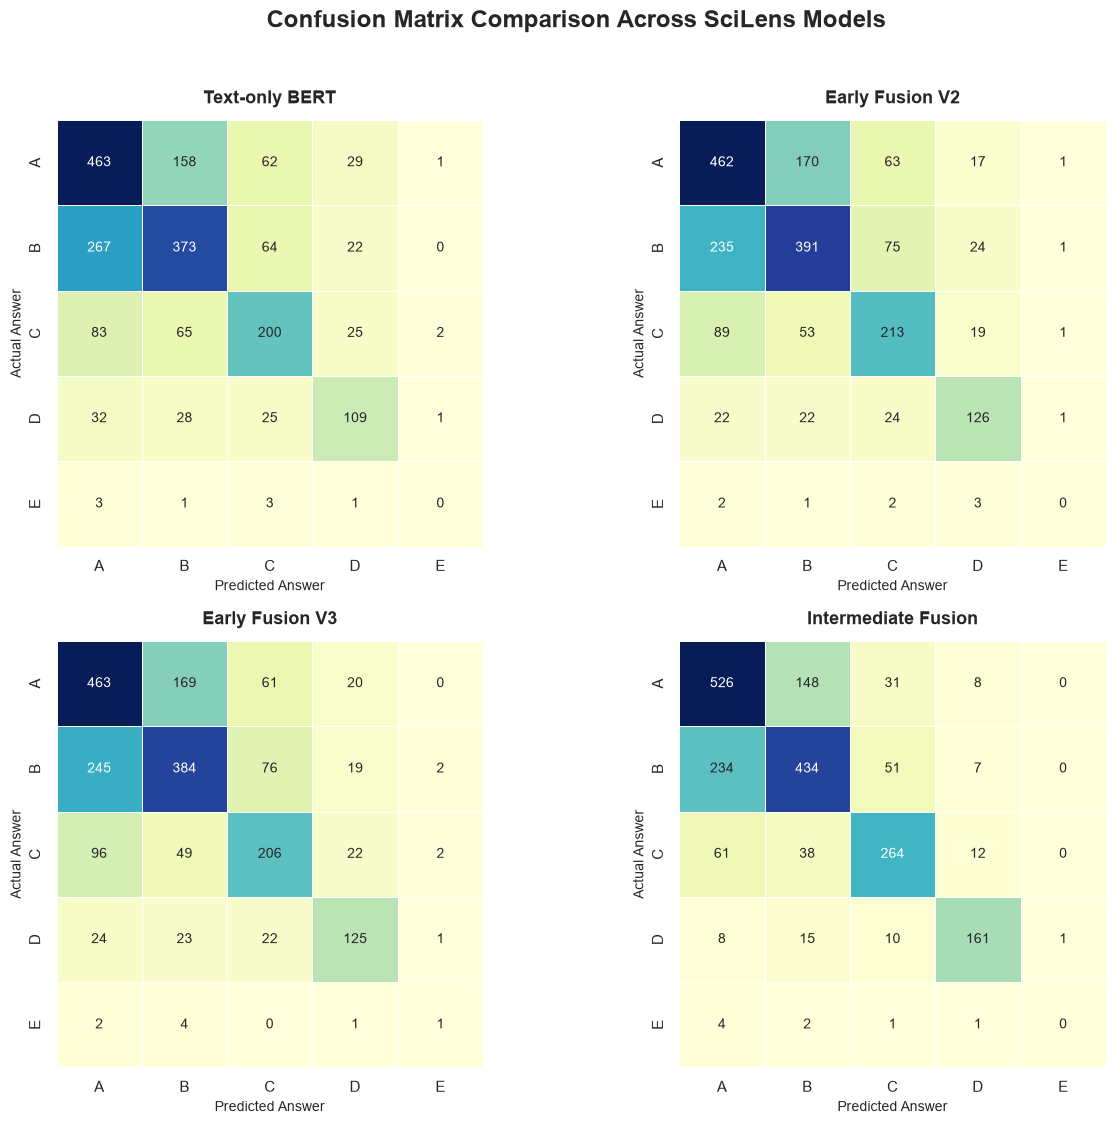

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

sns.set_theme(style="white", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

model_names = list(all_predictions.keys())

for ax, model_name in zip(axes, model_names):

    cm = all_predictions[model_name]["confusion_matrix"]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        linewidths=0.5,
        linecolor="white",
        cbar=False,
        square=True,
        xticklabels=["A", "B", "C", "D", "E"],
        yticklabels=["A", "B", "C", "D", "E"],
        ax=ax,
        annot_kws={"size": 10}
    )

    ax.set_title(model_name, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Predicted Answer", fontsize=10)
    ax.set_ylabel("Actual Answer", fontsize=10)

fig.suptitle(
    "Confusion Matrix Comparison Across SciLens Models",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    os.path.join(EVALUATION_DIR, "confusion_matrices_report.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [15]:

history_paths = {
    "Text-only BERT": "../results/text_only_bert/training_history.json",
    "Early Fusion V2": "../results/early_fusion_v2/training_history.json",
    "Early Fusion V3": "../results/early_fusion_v3/training_history.json",
    "Intermediate Fusion": "../results/intermediate_fusion_v1/training_history.json"
}

for name, path in history_paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")


Text-only BERT: FOUND
Early Fusion V2: FOUND
Early Fusion V3: NOT FOUND
Intermediate Fusion: NOT FOUND


Text-only BERT history keys: dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])
Early Fusion V2 history keys: dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])


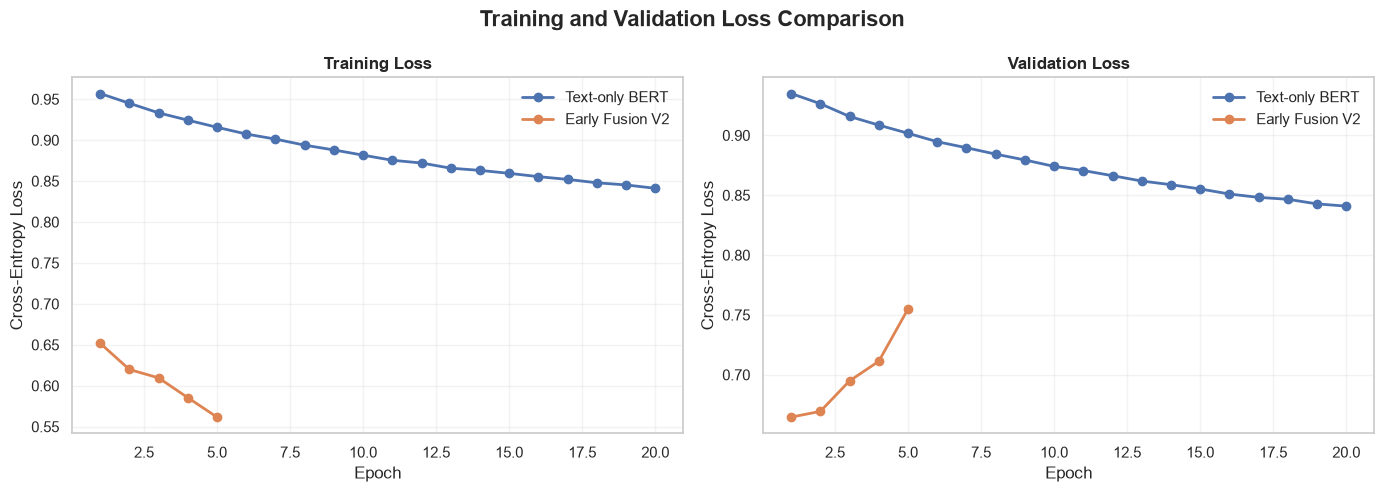

In [16]:

import json
import matplotlib.pyplot as plt
import seaborn as sns
import os

history_paths = {
    "Text-only BERT": "../results/text_only_bert/training_history.json",
    "Early Fusion V2": "../results/early_fusion_v2/training_history.json"
}

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, path in history_paths.items():

    with open(path, "r") as f:
        history = json.load(f)

    print(model_name, "history keys:", history.keys())

    # Adjust these keys if your JSON uses different names
    train_loss = history["train_loss"]
    val_loss = history["val_loss"]

    epochs = range(1, len(train_loss) + 1)

    axes[0].plot(
        epochs, train_loss,
        marker="o", linewidth=2, label=model_name
    )

    axes[1].plot(
        range(1, len(val_loss) + 1), val_loss,
        marker="o", linewidth=2, label=model_name
    )

axes[0].set_title("Training Loss", fontweight="bold")
axes[1].set_title("Validation Loss", fontweight="bold")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)

fig.suptitle(
    "Training and Validation Loss Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(EVALUATION_DIR, "training_validation_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


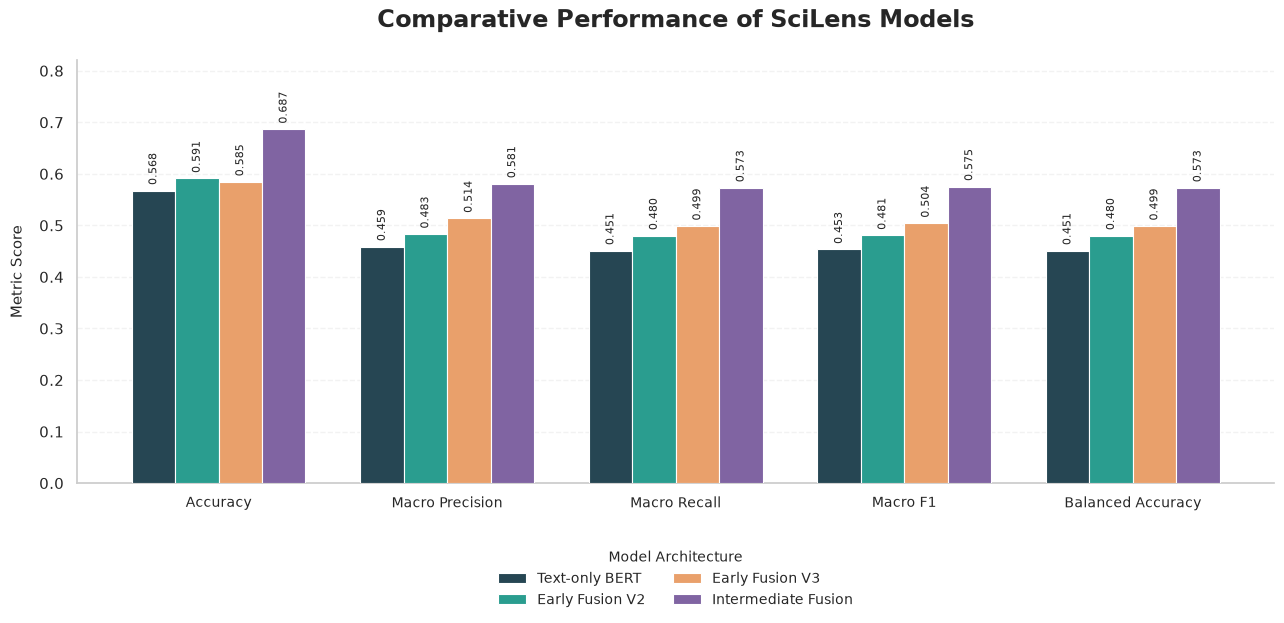

In [19]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Prepare evaluation data
comparison = pd.DataFrame(list(evaluation_results.values()))

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Balanced Accuracy"
]

models = comparison["Model"].tolist()

# Modern, professional colour palette
palette = {
    "Text-only BERT": "#264653",
    "Early Fusion V2": "#2A9D8F",
    "Early Fusion V3": "#E9A06B",
    "Intermediate Fusion": "#8064A2"
}

# Figure styling
sns.set_theme(style="whitegrid", font="DejaVu Sans")

fig, ax = plt.subplots(figsize=(13, 6.5))

x = np.arange(len(metrics))
width = 0.19

# Plot grouped bars
for i, model in enumerate(models):
    values = comparison.loc[
        comparison["Model"] == model, metrics
    ].values[0]

    offset = (i - (len(models) - 1) / 2) * width

    bars = ax.bar(
        x + offset,
        values,
        width=width,
        label=model,
        color=palette[model],
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    ax.bar_label(
        bars,
        labels=[f"{v:.3f}" for v in values],
        padding=4,
        fontsize=8,
        rotation=90
    )

# Titles and labels
ax.set_title(
    "Comparative Performance of SciLens Models",
    fontsize=17,
    fontweight="bold",
    pad=24
)

ax.set_ylabel("Metric Score", fontsize=11, labelpad=10)
ax.set_xlabel("")

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=10)

ax.set_ylim(0, 0.82)
ax.set_yticks(np.arange(0, 0.81, 0.1))

# Grid and borders
ax.grid(axis="y", linestyle="--", alpha=0.25, zorder=0)
ax.grid(axis="x", visible=False)

sns.despine(ax=ax, left=False, bottom=False)

# Legend
ax.legend(
    title="Model Architecture",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False,
    fontsize=10,
    title_fontsize=10
)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    os.path.join(EVALUATION_DIR, "scilens_model_comparison_final.png"),
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


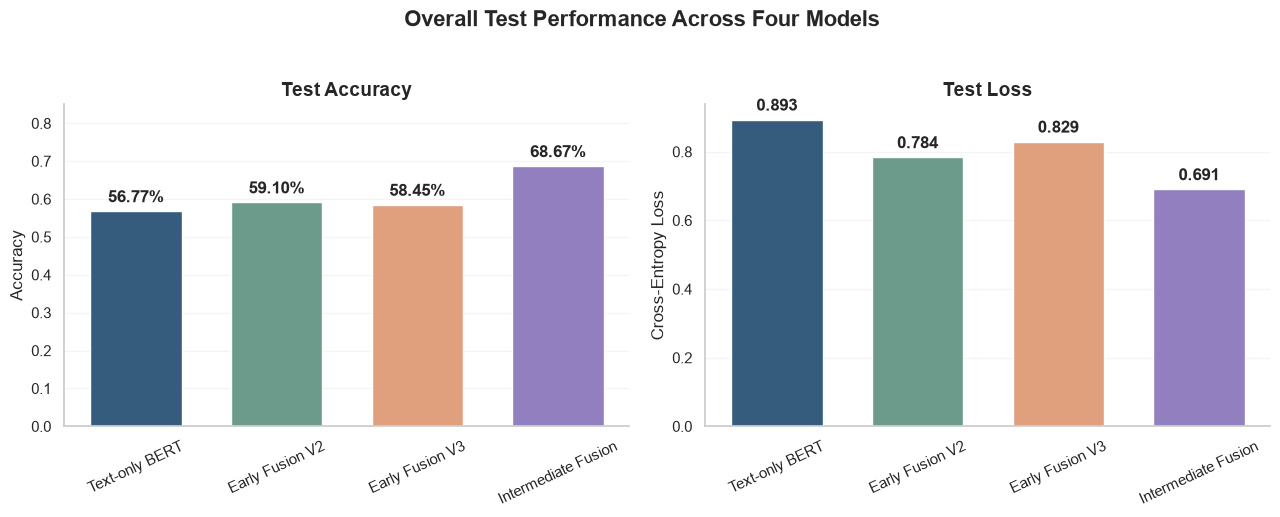

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Prepare results
performance_df = pd.DataFrame.from_dict(
    evaluation_results, orient="index"
)

model_names = performance_df.index.tolist()

accuracies = performance_df["Accuracy"].values
test_losses = performance_df["Test Loss"].values

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#355C7D", "#6C9A8B", "#E09F7D", "#927FBF"]

# Accuracy plot
bars1 = axes[0].bar(
    model_names, accuracies, color=colors, width=0.65
)

axes[0].set_title("Test Accuracy", fontweight="bold", fontsize=14)
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 0.85)
axes[0].tick_params(axis="x", rotation=25)

axes[0].bar_label(
    bars1,
    labels=[f"{v:.2%}" for v in accuracies],
    padding=4,
    fontweight="bold"
)

# Test loss plot
bars2 = axes[1].bar(
    model_names, test_losses, color=colors, width=0.65
)

axes[1].set_title("Test Loss", fontweight="bold", fontsize=14)
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].tick_params(axis="x", rotation=25)

axes[1].bar_label(
    bars2,
    labels=[f"{v:.3f}" for v in test_losses],
    padding=4,
    fontweight="bold"
)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

fig.suptitle(
    "Overall Test Performance Across Four Models",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

plt.savefig(
    os.path.join(EVALUATION_DIR, "model_test_performance.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


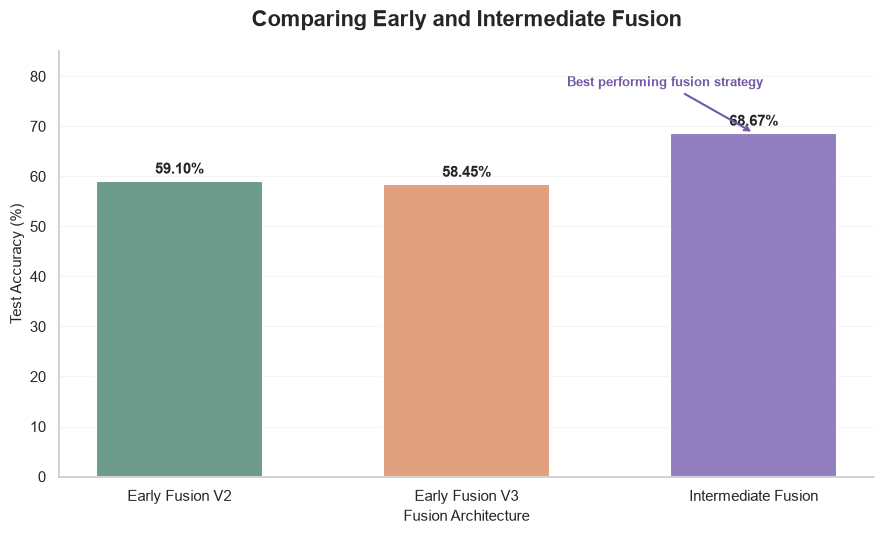

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Extract actual model results
comparison = pd.DataFrame(list(evaluation_results.values()))

fusion_models = [
    "Early Fusion V2",
    "Early Fusion V3",
    "Intermediate Fusion"
]

fusion_df = comparison[
    comparison["Model"].isin(fusion_models)
].copy()

# Preserve intended order
fusion_df["Model"] = pd.Categorical(
    fusion_df["Model"],
    categories=fusion_models,
    ordered=True
)

fusion_df = fusion_df.sort_values("Model")

# Plot
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 5.5))

colors = ["#6C9A8B", "#E09F7D", "#927FBF"]

bars = ax.bar(
    fusion_df["Model"].astype(str),
    fusion_df["Accuracy"] * 100,
    color=colors,
    width=0.58,
    edgecolor="white",
    linewidth=1.5
)

# Value labels
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.8,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Highlight best result
best_index = fusion_df["Accuracy"].idxmax()
best_position = list(fusion_df.index).index(best_index)

ax.annotate(
    "Best performing fusion strategy",
    xy=(best_position, fusion_df.loc[best_index, "Accuracy"] * 100),
    xytext=(best_position - 0.65, 78),
    arrowprops=dict(arrowstyle="->", color="#7059A5", lw=1.5),
    fontsize=9,
    color="#7059A5",
    fontweight="bold"
)

ax.set_title(
    "Comparing Early and Intermediate Fusion",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Test Accuracy (%)", fontsize=11)
ax.set_xlabel("Fusion Architecture", fontsize=11)
ax.set_ylim(0, 85)

ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

sns.despine(ax=ax)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EVALUATION_DIR,
        "fusion_strategy_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
